# SI 671 — 08 Forecasting Heterogeneity & Interpretation

**RQ4:** How does the incremental predictive value of historical OD network features vary across taxi zones, demand levels, and time?

This notebook is **evaluation only**, with **no model fitting and no Test-set access**. It consumes the **Validation predictions from Notebook 07** and defines demand strata using **January–August 2025 training-period pickups only**.

**Primary comparison:** M1 (enhanced temporal) vs M2 (+ OD Strength). Secondary: M2→M3 (+ Degree) and M3→M4 (+ HHI/flow flags). A positive MAE reduction means the newer model improves accuracy.

> Caveat: The September–October Validation period has already been used for model selection. All subgroup and bootstrap findings are **exploratory**; subgroup comparisons are not independent confirmatory tests. The Taxi dataset represents **yellow taxi pickups**, not total NYC mobility or Uber/Lyft demand.

## 0 — Configuration and required artifacts

Run from `Urban_Mobility_Mining/notebooks/` with the `si671-urban` kernel. The notebook does **not** overwrite 05/06/07 outputs. Training demand bands are based on the **full Jan–Aug nominal zone-hour panel**, not on validation outcomes; this denominator is explicitly documented and may differ slightly from the historical-coverage-filtered training sample used to fit the models.

In [1]:
from pathlib import Path
import json, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data/processed/cleaned_trips").is_dir():
    raise FileNotFoundError(f"Run from repository root or notebooks/: {ROOT}")

SOURCE = ROOT / "results/forecasting/enhanced_network_ablation"
PRED_PATH = SOURCE / "validation_predictions_m1_m4.parquet"
MANIFEST_PATH = SOURCE / "experiment_manifest.json"
LOOKUP_PATH = ROOT / "data/external/taxi_zone_lookup.csv"
CLEAN_DIR = ROOT / "data/processed/cleaned_trips"
OUT = ROOT / "results/forecasting/heterogeneity_rq4"
OUT.mkdir(parents=True, exist_ok=True)

for p in [PRED_PATH, MANIFEST_PATH, LOOKUP_PATH]:
    if not p.is_file():
        raise FileNotFoundError(f"Missing required file: {p}")

SEED = 671
N_BOOT = 2000
MODEL_CODES = ["m1", "m2", "m3", "m4"]
PAIRS = [("m1", "m2"), ("m2", "m3"), ("m3", "m4")]
TRAIN_START = pd.Timestamp("2025-01-01")
TRAIN_END = pd.Timestamp("2025-09-01")
VAL_START = pd.Timestamp("2025-09-01")
VAL_END = pd.Timestamp("2025-11-01")

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
assert not manifest.get("smoke_test", False), "Notebook 07 output was from a smoke test, not full diagnostics."
print("Project root:", ROOT)
print("Kernel:", sys.executable)
print("Python/pandas:", platform.python_version(), pd.__version__)
print("Prediction source:", PRED_PATH)
print("Output:", OUT)
print("Notebook 07 model:", manifest.get("best_validation_model"))

Project root: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining
Kernel: /opt/anaconda3/envs/si671-urban/bin/python
Python/pandas: 3.11.18 3.1.0
Prediction source: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/enhanced_network_ablation/validation_predictions_m1_m4.parquet
Output: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/heterogeneity_rq4
Notebook 07 model: M2 + OD Strength


## 1 — Load and audit paired Validation predictions

The evaluation uses **exactly the same zone-hour rows** for all models. No observations are dropped as a result of an individual model's error.

In [2]:
pred = pd.read_parquet(PRED_PATH)
needed = {"zone_id", "pickup_hour", "pickup_count"} | {f"pred_{m}" for m in MODEL_CODES}
assert needed.issubset(pred.columns), f"Missing columns: {sorted(needed - set(pred.columns))}"
pred = pred[["zone_id", "pickup_hour", "pickup_count"] + [f"pred_{m}" for m in MODEL_CODES]].copy()
pred["pickup_hour"] = pd.to_datetime(pred["pickup_hour"])
pred["zone_id"] = pred["zone_id"].astype(int)
pred = pred.sort_values(["pickup_hour", "zone_id"]).reset_index(drop=True)

assert not pred.duplicated(["zone_id", "pickup_hour"]).any()
assert pred["pickup_hour"].between(VAL_START, VAL_END, inclusive="left").all()
assert pred["pickup_count"].notna().all() and pred["pickup_count"].ge(0).all()
assert np.isfinite(pred[[f"pred_{m}" for m in MODEL_CODES]].to_numpy(dtype=float)).all()
assert pred["zone_id"].nunique() == 263
assert len(pred) == 385_032, f"Unexpected row count: {len(pred):,}"
if manifest.get("splits", {}).get("validation_rows") is not None:
    assert len(pred) == int(manifest["splits"]["validation_rows"])

for m in MODEL_CODES:
    pred[f"ae_{m}"] = (pred["pickup_count"] - pred[f"pred_{m}"]).abs()
    pred[f"se_{m}"] = (pred["pickup_count"] - pred[f"pred_{m}"]) ** 2
for old, new in PAIRS:
    pred[f"gain_{old}_to_{new}"] = pred[f"ae_{old}"] - pred[f"ae_{new}"]

baseline_rows = []
for m in MODEL_CODES:
    baseline_rows.append({"model":m.upper(), "n":len(pred),
                          "validation_MAE":pred[f"ae_{m}"].mean(),
                          "validation_RMSE":np.sqrt(pred[f"se_{m}"].mean())})
overall_df = pd.DataFrame(baseline_rows)
display(overall_df.round(5))
assert (pred["pickup_hour"].dt.strftime("%Y-%m").isin(["2025-09", "2025-10"])).all()
print("PASS: all predictions aligned on the same", f"{len(pred):,}", "zone-hours.")

,model,n,validation_MAE,validation_RMSE
0,M1,385032,3.32978,9.45644
1,M2,385032,3.31604,9.37402
2,M3,385032,3.34297,9.47219
3,M4,385032,3.34215,9.46551


PASS: all predictions aligned on the same 385,032 zone-hours.


## 2 — Training-only demand strata

Define each taxi zone's activity using its number of cleaned yellow-taxi pickups in **Jan 1–Aug 31, 2025**, divided by the total **nominal training hours**. No September–October target counts are used here. Zones are divided into three **equal-sized ranked groups**, which handles ties deterministically; the quantile cutoffs are descriptive, not an operational threshold.

We read only two columns from the eight training-month Parquet files. This is an inexpensive scan relative to retraining LightGBM.

In [3]:
zone_lookup = pd.read_csv(LOOKUP_PATH)
assert "LocationID" in zone_lookup.columns
valid_zones = sorted(set(zone_lookup["LocationID"].dropna().astype(int)) - {264, 265})
assert len(valid_zones) == 263
assert sorted(pred["zone_id"].unique().tolist()) == valid_zones

counts = pd.Series(0, index=pd.Index(valid_zones, name="zone_id"), dtype="int64")
source_rows = []
for month in range(1, 9):
    path = CLEAN_DIR / f"cleaned_2025-{month:02d}.parquet"
    if not path.exists():
        raise FileNotFoundError(path)
    trips = pd.read_parquet(path, columns=["tpep_pickup_datetime", "PULocationID"])
    month_start = pd.Timestamp(2025, month, 1)
    month_end = month_start + pd.DateOffset(months=1)
    relevant = trips["PULocationID"].isin(valid_zones)
    times = pd.to_datetime(trips.loc[relevant, "tpep_pickup_datetime"])
    if not times.between(month_start, month_end, inclusive="left").all():
        raise ValueError(f"Out-of-month pickup timestamp in {path.name}")
    monthly = trips.loc[relevant, "PULocationID"].value_counts().astype("int64")
    counts = counts.add(monthly, fill_value=0).astype("int64")
    source_rows.append({"month":f"2025-{month:02d}", "n_valid_zone_pickups":int(relevant.sum())})
    del trips, monthly, times

n_train_hours = len(pd.date_range(TRAIN_START, TRAIN_END, freq="h", inclusive="left"))
train_zone = pd.DataFrame({"zone_id":valid_zones})
train_zone["train_total_pickups"] = train_zone["zone_id"].map(counts).astype("int64")
train_zone["train_mean_pickups_per_hour"] = train_zone["train_total_pickups"] / n_train_hours
train_zone = train_zone.sort_values(["train_mean_pickups_per_hour", "zone_id"]).reset_index(drop=True)
# Equal-sized groups by ranked training demand. Ties are broken by zone_id.
train_zone["demand_group"] = pd.qcut(
    np.arange(len(train_zone)), 3, labels=["Low", "Medium", "High"]
).astype(str)
train_zone["demand_group"] = pd.Categorical(
    train_zone["demand_group"], categories=["Low","Medium","High"], ordered=True
)
assert train_zone["demand_group"].notna().all()
assert train_zone["train_total_pickups"].sum() == sum(r["n_valid_zone_pickups"] for r in source_rows)

pred = pred.merge(train_zone, on="zone_id", how="left", validate="many_to_one")
assert pred["demand_group"].notna().all()
print("Nominal training hours:", n_train_hours)
display(train_zone.groupby("demand_group", observed=True).agg(
    n_zones=("zone_id", "size"),
    min_train_mean=("train_mean_pickups_per_hour","min"),
    median_train_mean=("train_mean_pickups_per_hour","median"),
    max_train_mean=("train_mean_pickups_per_hour","max")
).round(3))

Nominal training hours: 5832


,n_zones,min_train_mean,median_train_mean,max_train_mean
demand_group,,,,
Low,88,0.000,0.227,0.827
Medium,87,0.838,1.583,4.341
High,88,4.575,32.615,237.187


## 3 — Helper: correctly weighted paired MAE comparisons

At each subgroup, calculate each model's **mean absolute error over individual zone-hours**, then subtract. A positive `abs_MAE_reduction` means improvement; the percentage uses the old model's subgroup MAE as denominator. This is **not** an average of per-zone percentages.

In [4]:
def compare_subgroups(frame, group_cols, old="m1", new="m2"):
    if isinstance(group_cols, str):
        group_cols = [group_cols]
    x = (frame.groupby(group_cols, observed=True, dropna=False)
         .agg(n=("pickup_count","size"),
              mean_actual_pickups=("pickup_count","mean"),
              old_MAE=(f"ae_{old}","mean"),
              new_MAE=(f"ae_{new}","mean"))
         .reset_index())
    x["abs_MAE_reduction"] = x["old_MAE"] - x["new_MAE"]
    x["relative_reduction_pct"] = np.where(
        x["old_MAE"] > 0,
        100 * x["abs_MAE_reduction"] / x["old_MAE"], np.nan
    )
    return x

all_gain = float(pred["gain_m1_to_m2"].mean())
assert np.isclose(all_gain, overall_df.iloc[0]["validation_MAE"] - overall_df.iloc[1]["validation_MAE"])
print(f"Overall M1→M2 absolute MAE reduction: {all_gain:+.6f}")

Overall M1→M2 absolute MAE reduction: +0.013741


## 4 — RQ4 A: Demand-level heterogeneity

Are strength features more useful in high-volume zones? We report absolute and relative MAE reduction and the share of all **total paired error reduction** by group. If one group gains more than 100% of the net total, other groups may be offsetting it.

,demand_group,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct,sum_error_reduction,share_of_net_gain_pct
0,Low,128832,0.30825,0.34374,0.34510,-0.00136,-0.39693,-175.77971,-3.32242
1,Medium,127368,1.90545,1.15288,1.16082,-0.00794,-0.68888,-1011.55392,-19.11941
2,High,128832,65.05007,8.46797,8.41769,0.05028,0.59380,6478.05085,122.44183


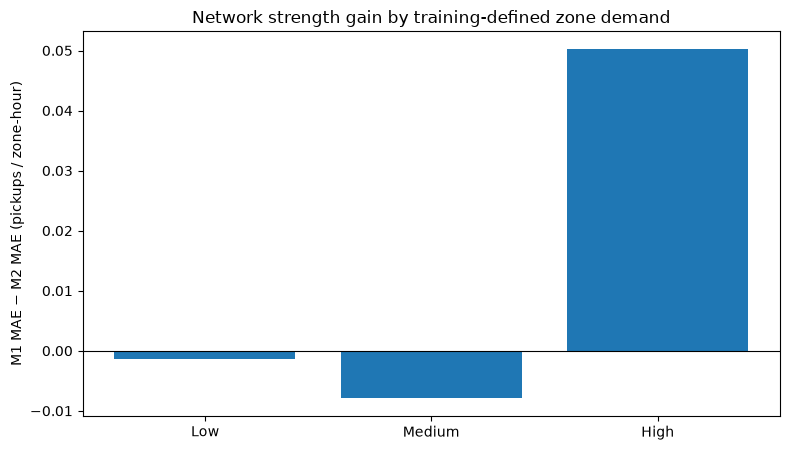

In [5]:
demand_df = compare_subgroups(pred, "demand_group")
demand_df["sum_error_reduction"] = demand_df["abs_MAE_reduction"] * demand_df["n"]
net_total = demand_df["sum_error_reduction"].sum()
demand_df["share_of_net_gain_pct"] = np.where(
    abs(net_total) > 1e-12, 100 * demand_df["sum_error_reduction"] / net_total, np.nan
)
display(demand_df.round(5))

fig, ax = plt.subplots(figsize=(8, 4.6))
order = ["Low", "Medium", "High"]
re = demand_df.set_index("demand_group").reindex(order)
ax.bar(order, re["abs_MAE_reduction"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("M1 MAE − M2 MAE (pickups / zone-hour)")
ax.set_title("Network strength gain by training-defined zone demand")
fig.tight_layout()
fig.savefig(OUT / "demand_group_mae_reduction.png", dpi=180)
plt.show()

## 5 — RQ4 B: Zone-level gains and interpretable taxi zone names

A zone-level MAE difference is computed from all of that zone's 1,464 validation hours. The borough and zone labels come directly from the local TLC zone lookup, not guessed from zone IDs. This notebook does not require a NYC shapefile; a geographic polygon map is deliberately omitted if geometry is unavailable.

M2 improves 99 of 263 zones
Largest improvements:


,zone_id,zone_label,demand_group,train_mean_pickups_per_hour,old_MAE,new_MAE,abs_MAE_reduction
137,138,138 · LaGuardia Airport,High,143.4837,27.7415,26.9245,0.8169
141,142,142 · Lincoln Square East,High,151.6139,22.4057,21.9140,0.4916
160,161,161 · Midtown Center,High,237.1871,24.6380,24.2887,0.3492
162,163,163 · Midtown North,High,138.2574,14.6206,14.3089,0.3117
185,186,186 · Penn Station/Madison Sq West,High,172.1761,26.2863,26.0053,0.2810
245,246,246 · West Chelsea/Hudson Yards,High,97.3416,13.7887,13.5235,0.2652
237,238,238 · Upper West Side North,High,94.9000,12.4616,12.2487,0.2129
230,231,231 · TriBeCa/Civic Center,High,74.6428,10.9222,10.7326,0.1897
131,132,132 · JFK Airport,High,231.6540,34.0909,33.9230,0.1678
139,140,140 · Lenox Hill East,High,101.9938,10.4981,10.3368,0.1613


Largest deteriorations:


,zone_id,zone_label,demand_group,train_mean_pickups_per_hour,old_MAE,new_MAE,abs_MAE_reduction
92,93,93 · Flushing Meadows-Corona Park,Medium,3.3608,2.9694,3.1283,-0.1588
144,145,145 · Long Island City/Hunters Point,High,11.4350,3.7360,3.8095,-0.0735
248,249,249 · West Village,High,120.0818,12.9012,12.9734,-0.0721
228,229,229 · Sutton Place/Turtle Bay North,High,83.9412,10.6961,10.7548,-0.0587
167,168,168 · Mott Haven/Port Morris,Medium,3.9486,1.7064,1.7532,-0.0467
94,95,95 · Forest Hills,Medium,3.6927,2.0305,2.0731,-0.0426
236,237,237 · Upper East Side South,High,229.9242,22.9221,22.9628,-0.0407
254,255,255 · Williamsburg (North Side),High,11.0060,3.3680,3.4039,-0.0359
67,68,68 · East Chelsea,High,139.6087,16.2008,16.2336,-0.0328
81,82,82 · Elmhurst,Medium,4.2426,1.5930,1.6240,-0.0310


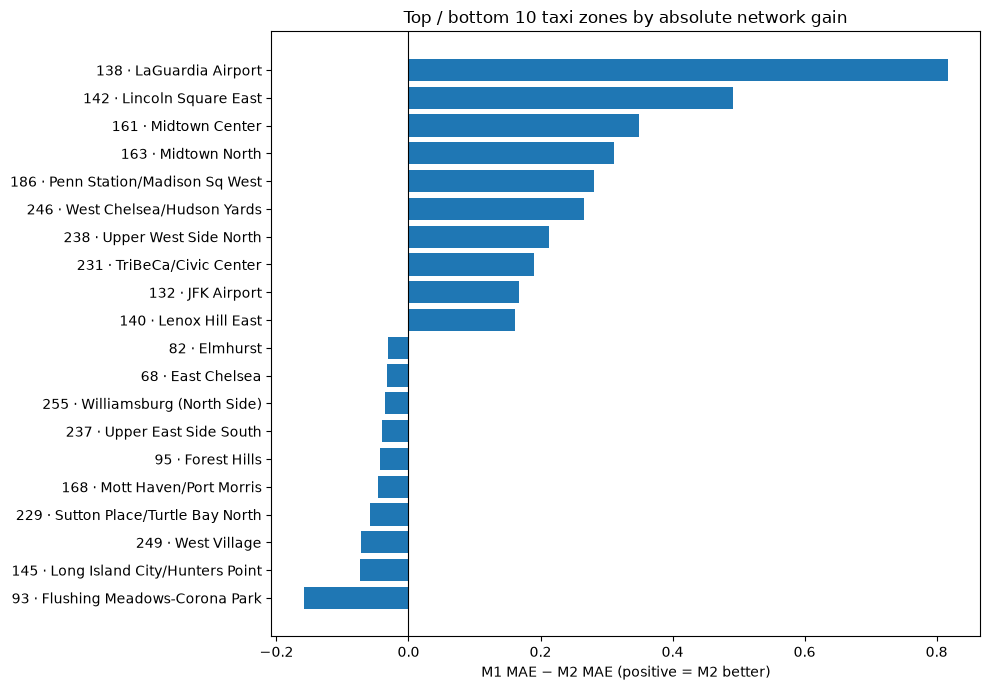

In [6]:
zone_df = compare_subgroups(pred, "zone_id")
zone_df = zone_df.merge(train_zone[["zone_id","demand_group","train_mean_pickups_per_hour"]],
                        on="zone_id", how="left", validate="one_to_one")
lookup_cols = ["LocationID"] + [x for x in ["Borough", "Zone", "service_zone"] if x in zone_lookup.columns]
zone_meta = zone_lookup[lookup_cols].drop_duplicates("LocationID").rename(columns={"LocationID":"zone_id"})
zone_df = zone_df.merge(zone_meta, on="zone_id", how="left", validate="one_to_one")
zone_df["zone_label"] = zone_df["zone_id"].astype(str)
if "Zone" in zone_df:
    zone_df["zone_label"] = zone_df["zone_label"] + " · " + zone_df["Zone"].fillna("Unknown")
print("M2 improves", int((zone_df["abs_MAE_reduction"] > 0).sum()),
      "of", len(zone_df), "zones")
print("Largest improvements:")
display(zone_df.nlargest(12, "abs_MAE_reduction")[["zone_id","zone_label","demand_group","train_mean_pickups_per_hour","old_MAE","new_MAE","abs_MAE_reduction"]].round(4))
print("Largest deteriorations:")
display(zone_df.nsmallest(12, "abs_MAE_reduction")[["zone_id","zone_label","demand_group","train_mean_pickups_per_hour","old_MAE","new_MAE","abs_MAE_reduction"]].round(4))

fig, ax = plt.subplots(figsize=(10, 7))
plot_df = pd.concat([zone_df.nlargest(10, "abs_MAE_reduction"),
                     zone_df.nsmallest(10, "abs_MAE_reduction")]).sort_values("abs_MAE_reduction")
ax.barh(plot_df["zone_label"], plot_df["abs_MAE_reduction"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("M1 MAE − M2 MAE (positive = M2 better)")
ax.set_title("Top / bottom 10 taxi zones by absolute network gain")
fig.tight_layout()
fig.savefig(OUT / "zone_top_bottom_mae_reduction.png", dpi=180, bbox_inches="tight")
plt.show()

## 6 — RQ4 C: Temporal heterogeneity

Evaluate separately by **hour of day**, **weekday vs weekend**, **day of week**, and **validation month**. These are pre-existing calendar attributes; subgroup analyses still remain exploratory.

/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_93801/3413972590.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  pred["day_of_week"] = pred["pickup_hour"].dt.dayofweek


,day_type,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct
0,Weekday,284040,22.35351,3.27655,3.26253,0.01402,0.42783
1,Weekend,100992,22.90920,3.47947,3.46651,0.01296,0.37251


,month,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct
0,2025-09,189360,22.40596,3.36393,3.34890,0.01502,0.44659
1,2025-10,195672,22.58956,3.29673,3.28423,0.01250,0.37917


,month,demand_group,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct
0,2025-09,Low,63360,0.31693,0.35105,0.35264,-0.00159,-0.45379
1,2025-09,Medium,62640,2.03788,1.20744,1.21557,-0.00813,-0.67339
2,2025-09,High,63360,64.63161,8.50879,8.45426,0.05453,0.64086
3,2025-10,Low,65472,0.29985,0.33667,0.33781,-0.00114,-0.33956
4,2025-10,Medium,64728,1.77728,1.10007,1.10783,-0.00776,-0.70534
5,2025-10,High,65472,65.45503,8.42848,8.38231,0.04617,0.54783


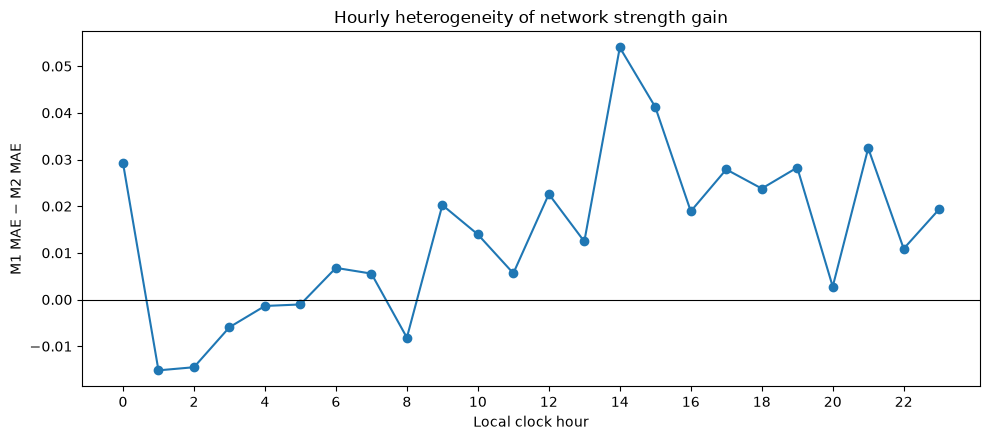

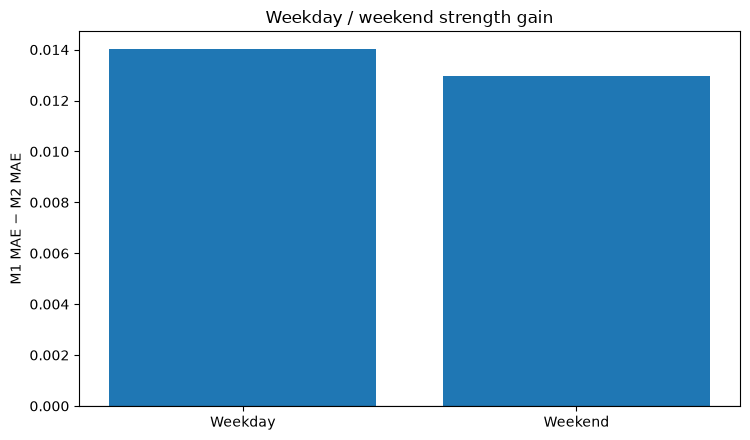

In [7]:
pred["hour"] = pred["pickup_hour"].dt.hour
pred["day_of_week"] = pred["pickup_hour"].dt.dayofweek
pred["day_type"] = np.where(pred["day_of_week"] >= 5, "Weekend", "Weekday")
pred["month"] = pred["pickup_hour"].dt.strftime("%Y-%m")

hourly_df = compare_subgroups(pred, "hour")
weekday_df = compare_subgroups(pred, "day_type")
dow_df = compare_subgroups(pred, "day_of_week")
month_df = compare_subgroups(pred, "month")
month_demand_df = compare_subgroups(pred, ["month", "demand_group"])

display(weekday_df.round(5))
display(month_df.round(5))
display(month_demand_df.round(5))

fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(hourly_df["hour"], hourly_df["abs_MAE_reduction"], marker="o")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(0,24,2))
ax.set_xlabel("Local clock hour")
ax.set_ylabel("M1 MAE − M2 MAE")
ax.set_title("Hourly heterogeneity of network strength gain")
fig.tight_layout()
fig.savefig(OUT / "hourly_mae_reduction.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7.6,4.5))
ax.bar(weekday_df["day_type"], weekday_df["abs_MAE_reduction"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("M1 MAE − M2 MAE")
ax.set_title("Weekday / weekend strength gain")
fig.tight_layout()
fig.savefig(OUT / "weekday_weekend_mae_reduction.png", dpi=180)
plt.show()

## 7 — RQ4 D: Error structure and zero-demand observations

The actual count is used here **only for post-hoc diagnostic grouping**, not for training-period demand strata or model selection. Zero vs nonzero splits describe where errors occur; they cannot be assumed known when forecasting an unseen future hour.

,actual_zero,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct,sample_fraction
0,Nonzero actual,237257,36.51288,5.12528,5.09583,0.02945,0.57463,0.6162
1,Zero actual,147775,0.00000,0.44704,0.45852,-0.01148,-2.56860,0.3838


,model,MAE,median_AE,p90_AE,p95_AE,p99_AE,bias_pred_minus_actual
0,M1,3.32978,0.77038,7.87386,15.75014,41.73251,-0.17672
1,M2,3.31604,0.77966,7.84035,15.67408,41.35098,-0.13170


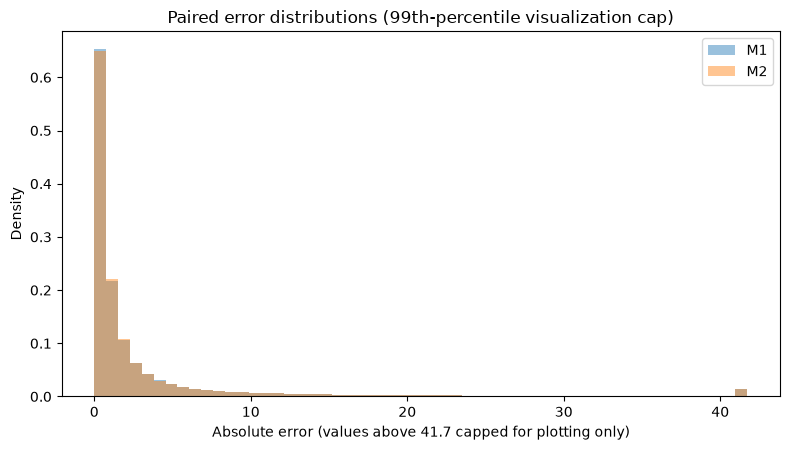

In [8]:
pred["actual_zero"] = np.where(pred["pickup_count"].eq(0), "Zero actual", "Nonzero actual")
zero_df = compare_subgroups(pred, "actual_zero")
zero_df["sample_fraction"] = zero_df["n"] / len(pred)
display(zero_df.round(5))

error_rows = []
for model in ["m1","m2"]:
    ae = pred[f"ae_{model}"]
    error_rows.append({"model":model.upper(), "MAE":ae.mean(),
        "median_AE":ae.median(),"p90_AE":ae.quantile(.90),
        "p95_AE":ae.quantile(.95),"p99_AE":ae.quantile(.99),
        "bias_pred_minus_actual":(pred[f"pred_{model}"] - pred["pickup_count"]).mean()})
error_df = pd.DataFrame(error_rows)
display(error_df.round(5))

fig, ax = plt.subplots(figsize=(8,4.6))
cap = float(max(pred["ae_m1"].quantile(.99), pred["ae_m2"].quantile(.99)))
cap = max(cap, 1.0)
ax.hist(np.minimum(pred["ae_m1"].to_numpy(), cap), bins=55, alpha=.45,
        label="M1", density=True)
ax.hist(np.minimum(pred["ae_m2"].to_numpy(), cap), bins=55, alpha=.45,
        label="M2", density=True)
ax.set_xlabel(f"Absolute error (values above {cap:.1f} capped for plotting only)")
ax.set_ylabel("Density")
ax.set_title("Paired error distributions (99th-percentile visualization cap)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "absolute_error_distribution.png", dpi=180)
plt.show()

## 8 — RQ4 E: Descriptive day-block bootstrap by training demand group

Resample the 61 Validation **calendar days**, keeping every zone-hour within a sampled day together. This respects shared daily patterns better than naive row bootstrap; it does **not** fully address week-to-week dependence, feature/model selection uncertainty or represent true out-of-sample inference. Interpret intervals as **exploratory descriptive uncertainty**.

,demand_group,observed_abs_MAE_reduction,ci_lower_2.5pct,ci_upper_97.5pct,fraction_positive,days,n_boot
0,ALL,0.013741,0.008072,0.019532,1.0,61,2000
1,Low,-0.001364,-0.001750,-0.000985,0.0,61,2000
2,Medium,-0.007942,-0.010793,-0.005404,0.0,61,2000
3,High,0.050283,0.033769,0.067483,1.0,61,2000


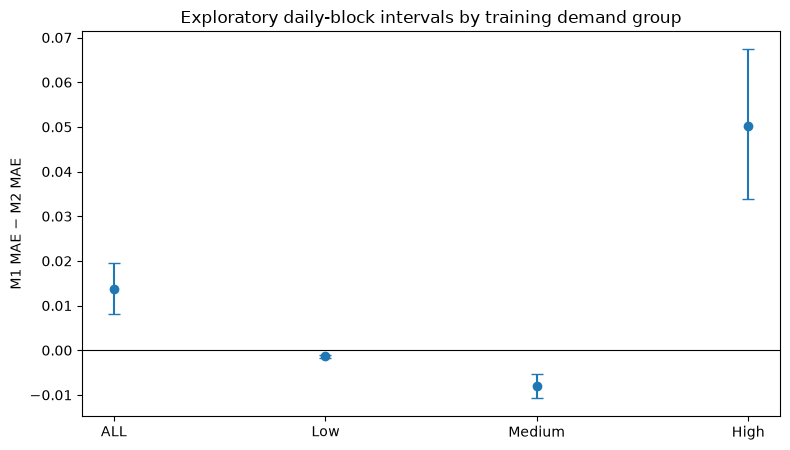

In [9]:
pred["date"] = pred["pickup_hour"].dt.normalize()
rng = np.random.default_rng(SEED)
boot_rows = []
for group_name in ["ALL", "Low", "Medium", "High"]:
    subset = pred if group_name == "ALL" else pred.loc[pred["demand_group"] == group_name]
    by_day = subset.groupby("date", observed=True).agg(
        n=("pickup_count", "size"),
        sum_gain=("gain_m1_to_m2", "sum")
    )
    assert len(by_day) == 61
    ix = rng.integers(0, len(by_day), size=(N_BOOT, len(by_day)))
    n_arr = by_day["n"].to_numpy(dtype=float)
    gain_arr = by_day["sum_gain"].to_numpy(dtype=float)
    boot = gain_arr[ix].sum(axis=1) / n_arr[ix].sum(axis=1)
    boot_rows.append({"demand_group":group_name,
                      "observed_abs_MAE_reduction":gain_arr.sum() / n_arr.sum(),
                      "ci_lower_2.5pct":np.quantile(boot,.025),
                      "ci_upper_97.5pct":np.quantile(boot,.975),
                      "fraction_positive":(boot > 0).mean(),
                      "days":len(by_day), "n_boot":N_BOOT})
boot_df = pd.DataFrame(boot_rows)
display(boot_df.round(6))

fig, ax = plt.subplots(figsize=(8,4.6))
x = np.arange(len(boot_df))
y = boot_df["observed_abs_MAE_reduction"].to_numpy()
lo = boot_df["ci_lower_2.5pct"].to_numpy()
hi = boot_df["ci_upper_97.5pct"].to_numpy()
ax.errorbar(x, y, yerr=[np.maximum(0,y-lo),np.maximum(0,hi-y)], fmt="o", capsize=4)
ax.axhline(0, color="black", linewidth=.8)
ax.set_xticks(x, boot_df["demand_group"])
ax.set_ylabel("M1 MAE − M2 MAE")
ax.set_title("Exploratory daily-block intervals by training demand group")
fig.tight_layout()
fig.savefig(OUT / "demand_group_bootstrap_intervals.png", dpi=180)
plt.show()

## 9 — Secondary feature-block comparisons

We also show M2→M3 (Degree) and M3→M4 (HHI + Flow Flags) by training-defined demand group. **Do not attribute M3→M4 gains to HHI alone**, because that increment includes flow availability indicators.

In [10]:
block_tables = []
for old,new in PAIRS:
    x = compare_subgroups(pred, "demand_group", old, new)
    x.insert(0, "comparison", f"{old.upper()}→{new.upper()}")
    block_tables.append(x)
feature_block_df = pd.concat(block_tables, ignore_index=True)
display(feature_block_df.round(5))

if "Borough" in pred.columns:
    borough_df = compare_subgroups(pred,"Borough")
else:
    borough_lkp = zone_meta[["zone_id", "Borough"]] if "Borough" in zone_meta.columns else None
    if borough_lkp is not None:
        borough_pred = pred.merge(borough_lkp, on="zone_id", how="left", validate="many_to_one")
        borough_df = compare_subgroups(borough_pred, "Borough")
    else:
        borough_df = pd.DataFrame()
if not borough_df.empty:
    display(borough_df.sort_values("abs_MAE_reduction", ascending=False).round(5))

,comparison,demand_group,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct
0,M1→M2,Low,128832,0.30825,0.34374,0.34510,-0.00136,-0.39693
1,M1→M2,Medium,127368,1.90545,1.15288,1.16082,-0.00794,-0.68888
2,M1→M2,High,128832,65.05007,8.46797,8.41769,0.05028,0.59380
3,M2→M3,Low,128832,0.30825,0.34510,0.34532,-0.00021,-0.06192
4,M2→M3,Medium,127368,1.90545,1.16082,1.16282,-0.00200,-0.17251
5,M2→M3,High,128832,65.05007,8.41769,8.49598,-0.07829,-0.93006
6,M3→M4,Low,128832,0.30825,0.34532,0.34539,-0.00007,-0.02045
7,M3→M4,Medium,127368,1.90545,1.16282,1.16188,0.00094,0.08104
8,M3→M4,High,128832,65.05007,8.49598,8.49440,0.00158,0.01858


,Borough,n,mean_actual_pickups,old_MAE,new_MAE,abs_MAE_reduction,relative_reduction_pct
3,Manhattan,101016,73.76824,8.91680,8.86307,0.05373,0.60257
4,Queens,101016,8.22362,1.97930,1.97257,0.00674,0.34040
5,Staten Island,29280,0.02893,0.05007,0.05053,-0.00046,-0.92767
1,Brooklyn,89304,3.53587,1.47825,1.48285,-0.00460,-0.31142
2,EWR,1464,0.78347,0.71120,0.71721,-0.00600,-0.84385
0,Bronx,62952,0.99577,0.74451,0.75061,-0.00610,-0.81931


## 10 — Save all RQ4 artifacts and a reproducible manifest

This writes only to `results/forecasting/heterogeneity_rq4/`. It never modifies or overwrites `enhanced_network_ablation/` or `final_rq3/`.

In [11]:
tables = {
    "overall_model_metrics.csv":overall_df,
    "train_zone_demand_groups.csv":train_zone,
    "demand_group_mae.csv":demand_df,
    "zone_mae_m1_m2.csv":zone_df,
    "hourly_mae.csv":hourly_df,
    "weekday_weekend_mae.csv":weekday_df,
    "day_of_week_mae.csv":dow_df,
    "monthly_mae.csv":month_df,
    "monthly_demand_group_mae.csv":month_demand_df,
    "zero_vs_nonzero_mae.csv":zero_df,
    "error_distribution_summary.csv":error_df,
    "demand_group_daily_bootstrap.csv":boot_df,
    "feature_block_by_demand.csv":feature_block_df,
}
if not borough_df.empty:
    tables["borough_mae.csv"] = borough_df
for fname, frame in tables.items():
    frame.to_csv(OUT / fname, index=False)

report = {
    "notebook":"08_forecasting_heterogeneity.ipynb",
    "task":"RQ4 descriptive validation-only heterogeneity",
    "input_predictions":str(PRED_PATH.relative_to(ROOT)),
    "input_07_manifest":str(MANIFEST_PATH.relative_to(ROOT)),
    "n_val_rows":int(len(pred)),
    "n_zones":int(pred["zone_id"].nunique()),
    "validation_start_inclusive":str(VAL_START),
    "validation_end_exclusive":str(VAL_END),
    "train_demand_start_inclusive":str(TRAIN_START),
    "train_demand_end_exclusive":str(TRAIN_END),
    "train_demand_definition":"Jan-Aug cleaned Yellow Taxi pickups / nominal clock hours; equal-sized ranked zone tertiles, ties by zone_id",
    "train_nominal_hours":int(n_train_hours),
    "primary_comparison":"M1→M2 (enhanced temporal + historical OD strength)",
    "secondary_comparisons":["M2→M3 Degree","M3→M4 HHI + Flow Flags"],
    "overall_validation_mae_reduction":float(all_gain),
    "n_zones_with_positive_mae_reduction":int((zone_df["abs_MAE_reduction"]>0).sum()),
    "bootstrap_resamples":N_BOOT,
    "seed":SEED,
    "test_set_accessed":False,
    "uncertainty":"Exploratory only: validation reused for model selection; intervals not confirmatory",
    "note":"Yellow taxi demand only, not total NYC mobility or Uber/Lyft",
}
(OUT / "rq4_manifest.json").write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", len(tables), "tables + figures + manifest to:", OUT)
for f in sorted(OUT.iterdir()):
    print(" -", f.name, f"({f.stat().st_size/1024:.1f} KiB)")

Saved 14 tables + figures + manifest to: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/heterogeneity_rq4
 - absolute_error_distribution.png (41.1 KiB)
 - borough_mae.csv (0.7 KiB)
 - day_of_week_mae.csv (0.8 KiB)
 - demand_group_bootstrap_intervals.png (36.5 KiB)
 - demand_group_daily_bootstrap.csv (0.4 KiB)
 - demand_group_mae.csv (0.6 KiB)
 - demand_group_mae_reduction.png (36.7 KiB)
 - error_distribution_summary.csv (0.3 KiB)
 - feature_block_by_demand.csv (1.1 KiB)
 - hourly_mae.csv (2.5 KiB)
 - hourly_mae_reduction.png (83.9 KiB)
 - monthly_demand_group_mae.csv (0.8 KiB)
 - monthly_mae.csv (0.3 KiB)
 - overall_model_metrics.csv (0.2 KiB)
 - rq4_manifest.json (1.2 KiB)
 - train_zone_demand_groups.csv (8.6 KiB)
 - weekday_weekend_mae.csv (0.3 KiB)
 - weekday_weekend_mae_reduction.png (32.0 KiB)
 - zero_vs_nonzero_mae.csv (0.4 KiB)
 - zone_mae_m1_m2.csv (49.0 KiB)
 - zone_top_bottom_mae_reduction.png (125.4 KiB)


## 11 — Results, Interpretation, and Discussion

### 11.1 Overview

This notebook investigates **RQ4: When and where do historical OD network features improve hourly NYC Yellow Taxi pickup demand forecasting?**

We compare the enhanced temporal baseline (M1) with the model incorporating historical OD strength features (M2), using 385,032 aligned zone-hour observations from September–October 2025.

Both models use Poisson LightGBM with the same training and validation samples and a maximum of 6,000 boosting rounds.

Overall, adding historical OD strength reduces validation MAE from **3.32978 to 3.31604**, corresponding to an absolute reduction of 0.01374 pickups per zone-hour (0.413%).

However, this improvement is not uniformly distributed across taxi zones or demand conditions.

### 11.2 Demand-Level Heterogeneity

Taxi zones are divided into three approximately equal-sized groups based on their average hourly Yellow Taxi pickup demand during the January–August 2025 training period.

| Demand Group | Zones | M1 MAE | M2 MAE | Relative MAE Reduction |
|---|---:|---:|---:|---:|
| Low | 88 | 0.34374 | 0.34510 | −0.397% |
| Medium | 87 | 1.15288 | 1.16082 | −0.689% |
| High | 88 | 8.46797 | 8.41769 | +0.594% |

**Finding 1 — Historical OD strength primarily benefits high-demand zones.**

The high-demand group achieves an absolute MAE reduction of 0.05028 pickups per zone-hour, while the low- and medium-demand groups experience small increases in prediction error.

The high-demand group accounts for approximately 122.4% of the net overall error reduction, indicating that its improvements outweigh the deterioration in the other groups.

This result suggests that historical OD flow information provides greater incremental forecasting value in zones with substantial Yellow Taxi activity.

### 11.3 Spatial Heterogeneity

**Finding 2 — The network-related improvement is concentrated in a minority of zones.**

Only 99 of 263 taxi zones (37.6%) achieve lower validation MAE with M2 than with M1.

The largest absolute improvements occur in several high-demand locations, including:

- LaGuardia Airport (Zone 138)
- Lincoln Square East (Zone 142)
- Midtown Center (Zone 161)
- Midtown North (Zone 163)
- Penn Station/Madison Sq West (Zone 186)

For example, LaGuardia Airport shows an absolute MAE reduction of approximately 0.817 pickups per zone-hour.

However, not all high-demand zones benefit. West Village and Upper East Side South are among the zones where errors increase after adding OD strength.

Therefore, historical demand volume is associated with the aggregate pattern of network benefits, but it does not fully explain zone-level variation.

### 11.4 Temporal Heterogeneity

**Finding 3 — Modest network-related improvements are observed across both validation months and day types.**

| Period | Relative MAE Reduction |
|---|---:|
| September | +0.447% |
| October | +0.379% |
| Weekdays | +0.428% |
| Weekends | +0.373% |

The direction of the overall improvement is consistent across September and October, as well as weekdays and weekends.

More importantly, the demand-group pattern is also consistent across both validation months: high-demand zones benefit, while low- and medium-demand zones generally experience slightly higher errors.

These findings provide descriptive evidence that the aggregate OD strength improvement is not restricted to one validation month or day type.

### 11.5 Error Distribution

**Finding 4 — OD strength improves forecasts for nonzero-demand observations but worsens errors for zero-demand observations.**

For observations with positive actual pickup counts, adding OD strength reduces MAE from 5.12528 to 5.09583, an improvement of approximately 0.575%.

For observations with zero actual pickups, MAE increases from 0.44704 to 0.45852, representing a deterioration of approximately 2.569%.

M2 also slightly reduces the 95th and 99th percentiles of absolute prediction error, although median absolute error increases from 0.77038 to 0.77966.

These results suggest that the overall improvement is associated more with reducing errors in active or relatively difficult forecasting cases than with uniformly improving predictions across all observations.

The zero/nonzero comparison is a retrospective error diagnostic, not a grouping rule available at prediction time.

### 11.6 Robustness and Uncertainty

A paired daily-block bootstrap with 2,000 resamples is used to summarize uncertainty in the observed MAE differences.

| Demand Group | Observed MAE Reduction | 95% Bootstrap Interval |
|---|---:|---|
| Low | −0.00136 | [−0.00175, −0.00099] |
| Medium | −0.00794 | [−0.01079, −0.00540] |
| High | +0.05028 | [+0.03377, +0.06748] |
| Overall | +0.01374 | [+0.00807, +0.01953] |

The resampling results support the descriptive pattern of positive improvement for high-demand zones and negative improvement for low- and medium-demand zones.

However, these intervals should be interpreted as exploratory uncertainty diagnostics because the same validation period was used during model development and selection.

### 11.7 Implications for RQ3 and RQ4

**RQ3 — Do historical network features improve forecasting accuracy?**

Historical OD strength provides a modest overall accuracy improvement beyond enhanced temporal features. In contrast, additional degree and HHI-related features do not improve overall validation performance under the evaluated model configuration.

**RQ4 — Where and when are network features most useful?**

The strongest evidence of incremental value appears in high-demand taxi zones, particularly several major Manhattan pickup areas and LaGuardia Airport.

The overall improvement persists across September and October and across weekdays and weekends, but the benefits are spatially concentrated rather than universal.

### 11.8 Limitations

- **Observational analysis:** Forecasting improvements describe predictive associations, not causal effects of taxi network connectivity.
- **Dataset scope:** Results apply to NYC Yellow Taxi records and cannot be generalized directly to Uber, Lyft, or total urban mobility demand.
- **Forecast horizon:** The models perform rolling one-hour-ahead prediction using historical observations available before each target hour.
- **Operational availability:** The network features assume historical completed-trip records are available without additional reporting delays.
- **DST handling:** Conservative exclusions are applied around daylight-saving transitions because local timestamps do not fully resolve repeated or missing clock hours.
- **Model convergence:** The evaluated LightGBM models reach their best validation iterations near the 6,000-round training cap.
- **Inference:** The uncertainty analysis does not account for all model-selection uncertainty or independent-year generalization.
- **Spatial mechanisms:** The observed association between demand intensity and network benefits does not by itself identify the underlying transportation mechanisms.

### 11.9 Conclusion

**Historical OD network strength provides modest additional forecasting value beyond a strong temporal baseline, but the gains are concentrated in high-demand taxi zones.**

Although only 37.6% of zones show lower validation MAE after adding OD strength, improvements in several heavily trafficked areas are sufficiently large to offset small deteriorations elsewhere.

The results demonstrate that **network-derived information does not benefit all locations equally**, and that its predictive value depends on the characteristics of the forecasting context.

These findings connect RQ3's aggregate network feature ablation with RQ4's analysis of spatial and temporal heterogeneity.